# Guidance Relevance Filter — funnel inspector

Load a finished run (`output.json` + `metrics.json` + `funnel.json`) and see how far each URL got, and why it died.

Pipeline order (each step only sees what the previous one passed):

1. `missing_body` / `empty_body` — no LLM
2. `lexicon_miss` — inclusion lexicon never fired, no LLM
3. `pass1_false` — Haiku said no
4. `pass2_drop` — Sonnet exclusion (incidental / homonym / wrong_domain)
5. `pass2_keep` / `pass2_unadjudicated` — kept

```bash
cd guidance-relevance-filter
uv sync --group notebook
uv run jupyter notebook inspect_funnel.ipynb
```

In [1]:
from __future__ import annotations

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 80)

# Point this at any guidance-relevance-filter run directory.
RUN_DIR = Path(
    "/Users/bram/Code/defra/content-audit-data-assets/steps/radia/runs/slurry-20260903"
)

STAGE_ORDER = [
    "missing_body",
    "empty_body",
    "lexicon_miss",
    "pass1_false",
    "pass2_drop",
    "pass2_unadjudicated",
    "pass2_keep",
]

print(RUN_DIR.resolve())
for name in ("output.json", "metrics.json", "funnel.json", "MODEL.md"):
    print(f"  {name:16} {(RUN_DIR / name).exists()}")

/Users/bram/Code/defra/content-audit-data-assets/steps/radia/runs/slurry-20260903
  output.json      True
  metrics.json     True
  funnel.json      True
  MODEL.md         True


In [2]:
def _cat(metrics: dict, pages: list[dict]) -> str:
    if metrics.get("category"):
        return metrics["category"]
    labels = (pages[0].get("meta_data") or {}).get("labels") or {}
    if labels:
        return next(iter(labels))
    return "slurry"


def load_run(run_dir: Path) -> tuple[pd.DataFrame, dict, dict]:
    pages = json.loads((run_dir / "output.json").read_text())
    metrics = json.loads((run_dir / "metrics.json").read_text()) if (run_dir / "metrics.json").exists() else {}
    funnel = json.loads((run_dir / "funnel.json").read_text()) if (run_dir / "funnel.json").exists() else {}
    cat = _cat(metrics, pages)
    rows = []
    for p in pages:
        md = p.get("meta_data") or {}
        f = md.get("funnel") or {}
        hits = ((md.get("selection_meta_body") or {}).get("hits_per_cat") or {}).get(cat) or []
        rows.append(
            {
                "url": p.get("url") or "",
                "title": md.get("title") or "",
                "document_type": md.get("document_type") or "",
                "primary_org": md.get("primary_publishing_organisation") or "",
                "organisations": list(md.get("organisations") or []),
                "stage": f.get("stage") or "",
                "label": (md.get("labels") or {}).get(cat),
                "pass1_score": f.get("pass1_score", (md.get("scores") or {}).get(cat)),
                "pass1_reason": f.get("pass1_reason") or "",
                "pass2_reason": f.get("pass2_reason") or "",
                "exclusion_hit": f.get("exclusion_hit") or "",
                "lexicon_hits": ", ".join(hits),
                "reason": (md.get("reasons") or {}).get(cat) or "",
            }
        )
    df = pd.DataFrame(rows)
    df["stage"] = pd.Categorical(df["stage"], categories=STAGE_ORDER, ordered=True)
    return df, metrics, funnel


def drop_reason(row: pd.Series) -> str:
    stage = str(row.get("stage") or "")
    if stage == "pass2_drop":
        tag = row.get("exclusion_hit") or ""
        return f"[{tag}] {row.get('pass2_reason') or row.get('reason') or ''}".strip()
    if stage == "pass1_false":
        return row.get("pass1_reason") or row.get("reason") or ""
    if stage in {"lexicon_miss", "empty_body", "missing_body"}:
        return row.get("reason") or stage
    return row.get("pass2_reason") or row.get("pass1_reason") or row.get("reason") or ""


pages, metrics, funnel_doc = load_run(RUN_DIR)
pages["drop_reason"] = pages.apply(drop_reason, axis=1)
cat = metrics.get("category") or funnel_doc.get("category") or "?"
display(Markdown(
    f"**{len(pages):,}** pages · category `{cat}` · "
    f"started `{metrics.get('started_at', '?')}` · "
    f"${metrics.get('cost_usd', '?')}`"
))
pages["stage"].value_counts(dropna=False).reindex(STAGE_ORDER).dropna().to_frame("n")

**23,454** pages · category `slurry` · started `2026-09-03T16:16:02` · $3.3429`

,n
stage,
missing_body,0
empty_body,366
lexicon_miss,22551
pass1_false,361
pass2_drop,38
pass2_unadjudicated,0
pass2_keep,138


## Organisations that got through

Keepers only (`pass2_keep` / `pass2_unadjudicated`). HTML publication chapters ship with empty org fields — we fill those from the parent `/government/publications/{slug}` row in the same run (every chapter in this corpus has a parent).

- **Primary** = `primary_publishing_organisation` (one count per page)
- **Any listed** = exploded `organisations` (a page can sit in more than one)

**138** pages got through · 69 html chapters inherited org from parent

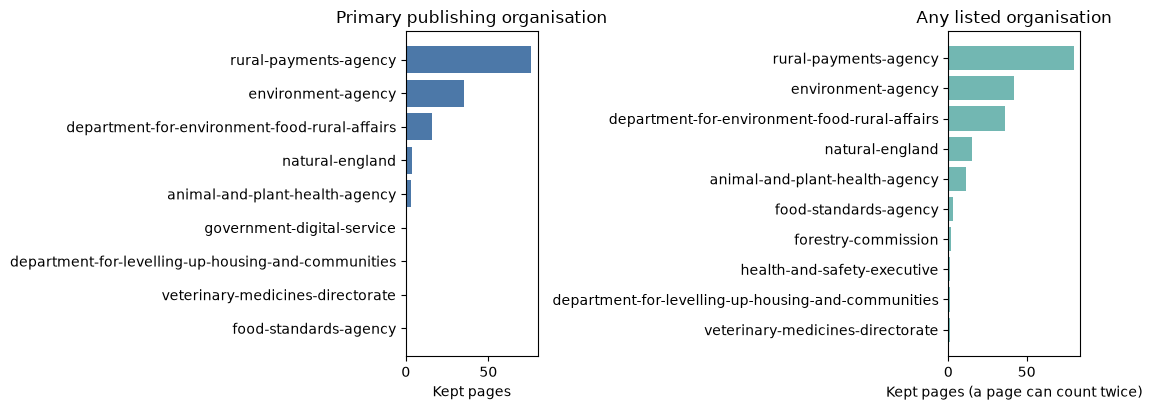

**Primary**

,n,pct
primary_org_filled,,
rural-payments-agency,76,55.1
environment-agency,35,25.4
department-for-environment-food-rural-affairs,16,11.6
natural-england,4,2.9
animal-and-plant-health-agency,3,2.2
government-digital-service,1,0.7
department-for-levelling-up-housing-and-communities,1,0.7
veterinary-medicines-directorate,1,0.7
food-standards-agency,1,0.7


**Any listed** (sums above 100% when pages have multiple orgs)

,pages,pct
organisations_filled,,
rural-payments-agency,80,58.0
environment-agency,42,30.4
department-for-environment-food-rural-affairs,36,26.1
natural-england,15,10.9
animal-and-plant-health-agency,11,8.0
food-standards-agency,3,2.2
forestry-commission,2,1.4
health-and-safety-executive,1,0.7
department-for-levelling-up-housing-and-communities,1,0.7


document_type,countryside_stewardship_grant,detailed_guide,farming_grant,guidance,guide,html_publication,manual_section
org_source,,,,,,,
own,9,29,1,12,1,0,17
parent,0,0,0,0,0,69,0


In [3]:
KEPT_STAGES = {"pass2_keep", "pass2_unadjudicated"}
kept = pages.loc[pages["stage"].isin(KEPT_STAGES)].copy()


def _publication_parent(url: str) -> str | None:
    parts = url.rstrip("/").split("/")
    try:
        i = parts.index("publications")
    except ValueError:
        return None
    if len(parts) > i + 2:
        return "/".join(parts[: i + 2])
    return None


by_url = pages.assign(_key=pages["url"].str.rstrip("/")).drop_duplicates("_key").set_index("_key")


def _inherit_orgs(row: pd.Series) -> pd.Series:
    primary = row["primary_org"]
    orgs = list(row["organisations"] or [])
    source = "own"
    if not primary and not orgs:
        parent = _publication_parent(row["url"])
        if parent is not None and parent in by_url.index:
            p = by_url.loc[parent]
            primary = p["primary_org"] or ""
            orgs = list(p["organisations"] or [])
            source = "parent" if (primary or orgs) else "none"
        else:
            source = "none"
    return pd.Series(
        {
            "primary_org_filled": primary or "(none)",
            "organisations_filled": orgs,
            "org_source": source,
        }
    )


kept = kept.join(kept.apply(_inherit_orgs, axis=1))
n_kept = len(kept)
display(Markdown(
    f"**{n_kept}** pages got through"
    + (f" · {int((kept['org_source'] == 'parent').sum())} html chapters inherited org from parent"
       if (kept["org_source"] == "parent").any() else "")
))

primary = (
    kept["primary_org_filled"]
    .value_counts()
    .rename("n")
    .to_frame()
    .assign(pct=lambda d: (d["n"] / n_kept * 100).round(1))
)
any_org = (
    kept["organisations_filled"]
    .explode()
    .fillna("(none)")
    .replace("", "(none)")
    .value_counts()
    .rename("pages")
    .to_frame()
    .assign(pct=lambda d: (d["pages"] / n_kept * 100).round(1))
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh(list(primary.index[::-1]), primary["n"].to_numpy()[::-1], color="#4C78A8")
axes[0].set_title("Primary publishing organisation")
axes[0].set_xlabel("Kept pages")
axes[1].barh(list(any_org.index[::-1]), any_org["pages"].to_numpy()[::-1], color="#72B7B2")
axes[1].set_title("Any listed organisation")
axes[1].set_xlabel("Kept pages (a page can count twice)")
fig.tight_layout()
plt.show()

display(Markdown("**Primary**"))
display(primary)
display(Markdown("**Any listed** (sums above 100% when pages have multiple orgs)"))
display(any_org)
display(kept.groupby(["org_source", "document_type"]).size().unstack(fill_value=0))


## Remaining, in pipeline order

Left bar = still in after that step. The 99-style headline is the **last** bar, not a first cut.

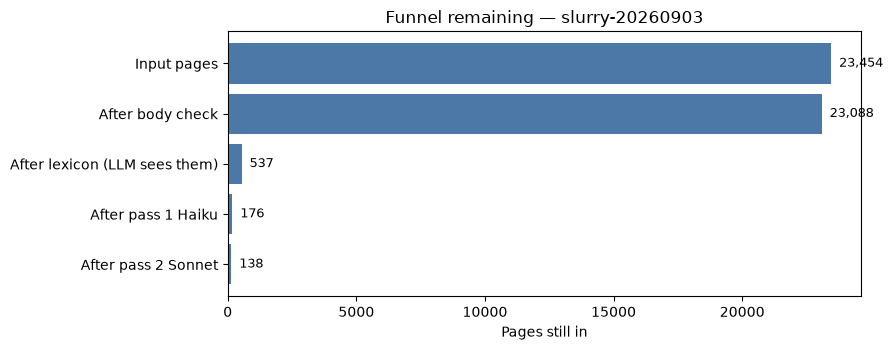

,step,still_in,dropped_here
0,Input pages,23454,0
1,After body check,23088,366
2,After lexicon (LLM sees them),537,22551
3,After pass 1 Haiku,176,361
4,After pass 2 Sonnet,138,38


In [4]:
n = len(pages)
n_missing = int((pages["stage"] == "missing_body").sum())
n_empty = int((pages["stage"] == "empty_body").sum())
n_lex_miss = int((pages["stage"] == "lexicon_miss").sum())
n_p1_false = int((pages["stage"] == "pass1_false").sum())
n_p2_drop = int((pages["stage"] == "pass2_drop").sum())
n_keep = int(pages["stage"].isin(["pass2_keep", "pass2_unadjudicated"]).sum())

remaining = pd.DataFrame(
    [
        ("Input pages", n, 0),
        ("After body check", n - n_missing - n_empty, n_missing + n_empty),
        ("After lexicon (LLM sees them)", n_p1_false + n_p2_drop + n_keep, n_lex_miss),
        ("After pass 1 Haiku", n_p2_drop + n_keep, n_p1_false),
        ("After pass 2 Sonnet", n_keep, n_p2_drop),
    ],
    columns=["step", "still_in", "dropped_here"],
)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(remaining["step"][::-1], remaining["still_in"][::-1], color="#4C78A8")
ax.set_xlabel("Pages still in")
ax.set_title(f"Funnel remaining — {RUN_DIR.name}")
for y, val in enumerate(remaining["still_in"][::-1]):
    ax.text(val, y, f"  {val:,}", va="center", fontsize=9)
fig.tight_layout()
plt.show()
remaining

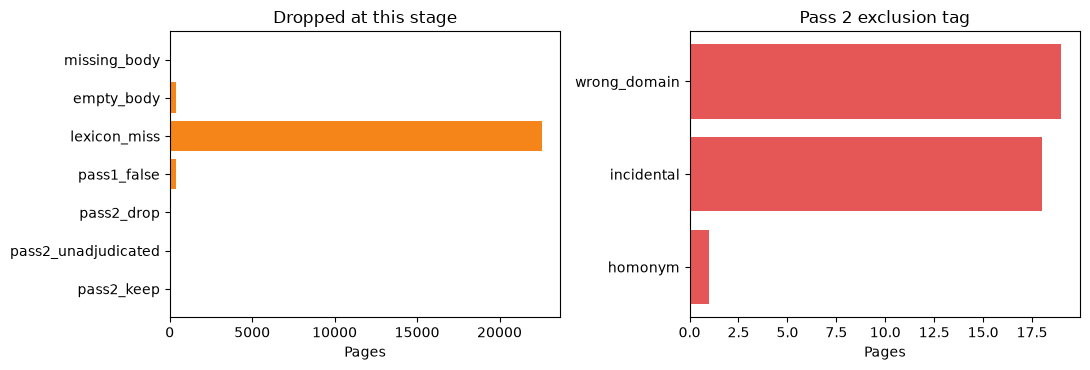

,dropped
stage,
missing_body,0
empty_body,366
lexicon_miss,22551
pass1_false,361
pass2_drop,38
pass2_unadjudicated,0
pass2_keep,0


,pass2_drop
exclusion_hit,
wrong_domain,19
incidental,18
homonym,1


In [5]:
dropped = pages.loc[~pages["stage"].isin(["pass2_keep", "pass2_unadjudicated"])]
by_stage = (
    dropped["stage"].value_counts().reindex(STAGE_ORDER).dropna().astype(int)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh([str(s) for s in by_stage.index[::-1]], by_stage.to_numpy()[::-1], color="#F58518")
axes[0].set_title("Dropped at this stage")
axes[0].set_xlabel("Pages")

ex = pages.loc[pages["stage"] == "pass2_drop", "exclusion_hit"].value_counts()
if len(ex):
    axes[1].barh(list(ex.index[::-1]), ex.to_numpy()[::-1], color="#E45756")
    axes[1].set_title("Pass 2 exclusion tag")
    axes[1].set_xlabel("Pages")
else:
    axes[1].set_visible(False)
fig.tight_layout()
plt.show()

display(by_stage.to_frame("dropped"))
if len(ex):
    display(ex.to_frame("pass2_drop"))

## Browse drops

Set `STAGE` and `Q` and re-run. `lexicon_miss` is ~22k rows — search or you will drown.

In [6]:
STAGE = "pass2_drop"  # or pass1_false / lexicon_miss / pass2_keep / empty_body / ""
Q = ""  # substring on url or title, case-insensitive
EXCLUSION = ""  # incidental | homonym | wrong_domain | ""
LIMIT = 50

view = pages
if STAGE:
    view = view[view["stage"] == STAGE]
if EXCLUSION:
    view = view[view["exclusion_hit"] == EXCLUSION]
if Q:
    q = Q.lower()
    view = view[view["url"].str.lower().str.contains(q, na=False) | view["title"].str.lower().str.contains(q, na=False)]

cols = ["stage", "title", "url", "lexicon_hits", "pass1_score", "exclusion_hit", "drop_reason"]
print(f"{len(view):,} rows (showing {min(LIMIT, len(view))})")
view[cols].head(LIMIT)

38 rows (showing 38)


,stage,title,url,lexicon_hits,pass1_score,exclusion_hit,drop_reason
588,pass2_drop,Contact Defra,https://www.gov.uk/guidance/contact-defra,Slurry,0.20,incidental,"[incidental] The only mention of slurry is in a single contact directory table row listing 'regulations for nitrate vulnerable zones (NVZs), soil, silage an..."
668,pass2_drop,BN11: Planting new hedges,https://www.gov.uk/countryside-stewardship-grants/planting-new-hedges-bn11,Slurry,0.20,incidental,"[incidental] The single mention of slurry stores appears only as one example location where hedgerow planting may help capture ammonia emissions, with no di..."
719,pass2_drop,Public rights of way: landowner responsibilities,https://www.gov.uk/guidance/public-rights-of-way-landowner-responsibilities,Slurry,0.20,incidental,[incidental] The single mention of 'slurry lagoons' appears only as an example of a potential hazard requiring a warning sign for public rights of way users...
1071,pass2_drop,Nuisance smells: how councils deal with complaints,https://www.gov.uk/guidance/nuisance-smells-how-councils-deal-with-complaints,"Slurry, Animal by-products",0.40,incidental,[incidental] The page is about how councils handle statutory nuisance smell complaints; 'spreading slurry or sludge onto land' appears only as a single bull...
1416,pass2_drop,RP18: Above ground tanks,https://www.gov.uk/countryside-stewardship-grants/above-ground-tanks-rp18,Slurry,0.60,incidental,"[incidental] The page is about above-ground rainwater collection tanks, and explicitly states 'You cannot use this item to collect slurry or contaminated wa..."
3592,pass2_drop,How to do the SFI actions for nutrient management,https://www.gov.uk/guidance/how-to-do-the-sfi-actions-for-nutrient-management,Slurry,0.30,incidental,"[incidental] Slurry appears exactly once in a list of organic nutrient sources ('legumes, manure, slurry or digestate') as a passing example within a broade..."
4238,pass2_drop,Relevant convictions for environmental permits,https://www.gov.uk/guidance/relevant-convictions-for-environmental-permits,"Slurry, Animal by-products",0.30,incidental,[incidental] The page is about declaring relevant convictions for environmental permits and only mentions slurry incidentally as part of a legislative list ...
5698,pass2_drop,How to operate an animal by-product (ABP) processing facility,https://www.gov.uk/guidance/how-to-operate-an-animal-by-product-abp-processing-facility,Animal by-products,0.30,wrong_domain,"[wrong_domain] This page is entirely about industrial heat-treatment processing methods (pressure sterilisation, temperature/time combinations, GTH marking,..."
5961,pass2_drop,Guidelines and guidance on the responsible use of veterinary medicines,https://www.gov.uk/guidance/guidelines-and-guidance-on-the-responsible-use-of-antibiotics,Slurry,0.20,incidental,[incidental] The page is a directory of antimicrobial/antibiotic guidance links with no substantive slurry content; the single mention of 'Handling of manur...
6512,pass2_drop,"Generating energy from waste, including anaerobic digestion",https://www.gov.uk/guidance/generating-energy-from-waste-including-anaerobic-digestion,"Slurry, Animal manure, Animal by-products",0.70,wrong_domain,[wrong_domain] The page's single mention of 'animal manure and slurry' is purely incidental — it appears in one sentence listing AD feedstocks alongside sew...


## One URL

Paste a gov.uk URL (original or chapter). Matches exact, then substring.

In [7]:
URL = "https://www.gov.uk/government/publications/dewatering-bentonite-slurry-waste-in-a-bentonite-recirculation-plant-rps-272/dewatering-bentonite-slurry-waste-in-a-bentonite-recirculation-plant-rps-272"

needle = URL.strip().rstrip("/")
hit = pages[pages["url"].str.rstrip("/") == needle]
if hit.empty:
    hit = pages[pages["url"].str.contains(needle.split("/")[-1], case=False, na=False)]

if hit.empty:
    display(Markdown(f"Not in this run: `{needle}`"))
else:
    for _, row in hit.iterrows():
        display(Markdown(
            f"### {row['title'] or row['url']}\n"
            f"- **stage:** `{row['stage']}` · **label:** `{row['label']}`\n"
            f"- **url:** {row['url']}\n"
            f"- **lexicon:** {row['lexicon_hits'] or '—'}\n"
            f"- **pass 1 score:** {row['pass1_score']}\n"
            f"- **exclusion:** {row['exclusion_hit'] or '—'}\n\n"
            f"**Drop / keep reason**\n\n{row['drop_reason'] or '—'}\n"
        ))
        if row["pass1_reason"] and row["stage"] in {"pass2_drop", "pass2_keep", "pass2_unadjudicated"}:
            display(Markdown(f"**Pass 1 reason**\n\n{row['pass1_reason']}"))

### Dewatering bentonite slurry waste in a bentonite recirculation plant: RPS 272
- **stage:** `pass1_false` · **label:** `False`
- **url:** https://www.gov.uk/government/publications/dewatering-bentonite-slurry-waste-in-a-bentonite-recirculation-plant-rps-272/dewatering-bentonite-slurry-waste-in-a-bentonite-recirculation-plant-rps-272
- **lexicon:** Slurry
- **pass 1 score:** 0.1
- **exclusion:** —

**Drop / keep reason**

While the page contains the word 'slurry' multiple times, it specifically concerns bentonite slurry from construction piling and retaining wall works, not animal slurry, animal manure, or animal by-products as defined in the inclusion criteria. This is industrial/construction waste rather than livestock-related waste.


## Optional: join a URL list (e.g. Duncan)

CSV needs an `Original URL` column (Duncan’s file) or a single `url` column. Shows where *those* URLs died. Organisations for the gold list are in the next section.

In [8]:
import csv
import re
from urllib.parse import urlparse

GOLD_CSV = Path("/Users/bram/Code/defra/ai-eu-trade-accelerator/docs/Simple Duncans List.csv")
# GOLD_CSV = None  # skip


def govuk_path(url: str) -> str | None:
    url = (url or "").strip()
    if not url:
        return None
    m = re.search(r"https?:/+www\.gov\.uk(/[^?\s#]*)", url)
    path = m.group(1).rstrip("/") if m else urlparse(url).path.rstrip("/")
    if path.startswith("/api/content/"):
        path = path[len("/api/content"):]
    return path or None


if GOLD_CSV and GOLD_CSV.exists():
    by_path = {}
    for _, r in pages.iterrows():
        path = govuk_path(r["url"])
        if path:
            by_path[path] = r

    gold_rows = []
    with GOLD_CSV.open() as fh:
        reader = csv.DictReader(fh)
        fields = reader.fieldnames or []
        orig_key = "Original URL" if "Original URL" in fields else ("url" if "url" in fields else fields[0])
        res_key = "Resolved URL" if "Resolved URL" in fields else None
        seen: set[str] = set()
        for rec in reader:
            orig = (rec.get(orig_key) or "").strip()
            if orig.rstrip("/") in seen:
                continue
            seen.add(orig.rstrip("/"))
            res = (rec.get(res_key) or "").strip() if res_key else ""
            hit = None
            how = "not_in_corpus"
            for src, kind in ((orig, "original"), (res, "resolved")):
                path = govuk_path(src)
                if path and path in by_path:
                    hit = by_path[path]
                    how = f"exact_{kind}"
                    break
            gold_rows.append(
                {
                    "original": orig,
                    "match": how,
                    "stage": hit["stage"] if hit is not None else "not_in_corpus",
                    "title": (hit["title"] if hit is not None else "") or orig.rstrip("/").split("/")[-1],
                    "drop_reason": drop_reason(hit) if hit is not None else "never in with_body.json",
                    "exclusion_hit": hit["exclusion_hit"] if hit is not None else "",
                    "corpus_url": hit["url"] if hit is not None else "",
                    "primary_org": (hit["primary_org"] if hit is not None else "") or "",
                    "organisations": list(hit["organisations"]) if hit is not None else [],
                }
            )
    gold = pd.DataFrame(gold_rows)
    gold["stage"] = pd.Categorical(
        gold["stage"], categories=["not_in_corpus", *STAGE_ORDER], ordered=True
    )
    display(Markdown(f"**{GOLD_CSV.name}** — {len(gold)} unique originals"))
    display(gold["stage"].value_counts(dropna=False).sort_index().to_frame("n"))
    display(gold[["stage", "primary_org", "title", "match", "exclusion_hit", "drop_reason"]].sort_values("stage"))
else:
    print("No GOLD_CSV — skip.")

**Simple Duncans List.csv** — 219 unique originals

,n
stage,
not_in_corpus,32
missing_body,0
empty_body,0
lexicon_miss,24
pass1_false,48
pass2_drop,15
pass2_unadjudicated,0
pass2_keep,100


,stage,primary_org,title,match,exclusion_hit,drop_reason
146,not_in_corpus,,nutrient-pollution-reducing-the-impact-on-protected-sites,not_in_corpus,,never in with_body.json
93,not_in_corpus,,general-licence-for-the-movement-of-poultry-carcases-for-disposal-from-premises-in-a-protection-zone-in-england-wales-or-scotland-exd339hpaigb,not_in_corpus,,never in with_body.json
92,not_in_corpus,,general-licence-for-the-movement-of-poultry-by-products-and-hatching-eggs-for-disposal-from-premises-in-a-protection-or-surveillance-zone-exd389hpai,not_in_corpus,,never in with_body.json
56,not_in_corpus,,apply-for-a-large-countryside-productivity-grant-alpha-reassessment,not_in_corpus,,never in with_body.json
90,not_in_corpus,,general-licence-for-the-movement-of-hatching-eggs-from-a-premises-in-a-protection-zone-or-surveillance-zone-to-a-designated-premises-for-use-for-scien,not_in_corpus,,never in with_body.json
...,...,...,...,...,...,...
105,pass2_keep,veterinary-medicines-directorate,Handling of manure and slurry to reduce antibiotic resistance,exact_original,none,"The page explicitly discusses animal slurry storage (3-month holding periods, slurry tanks), land application controls (spreading practices, buffer periods,..."
106,pass2_keep,rural-payments-agency,Hedgerow management rules: buffer strips,exact_original,incidental,Slurry appears in the definitions section as a listed type of fertiliser that must not be applied within 2 metres of a hedgerow buffer strip. Although the p...
108,pass2_keep,rural-payments-agency,How the Improving Farm Productivity grants work,exact_original,none,"The page explicitly references 'slurry project' as a distinct eligible project type under the Improving Farm Productivity grants scheme, with specific fundi..."
83,pass2_keep,rural-payments-agency,Eligible and ineligible items,exact_original,none,"The page contains a dedicated 'Slurry – Mild acidification equipment' section describing eligible equipment for treating animal slurry (acid storage, dosing..."


## Duncan — organisations

Same inherit rule as keepers: empty org on an `html_publication` chapter is filled from the parent `/government/publications/{slug}` if that parent is in the run. URLs that never made `with_body.json` stay `(none)`.

**219** unique Duncan originals · 110 own org · 77 inherited from parent · 32 unknown (not in corpus)

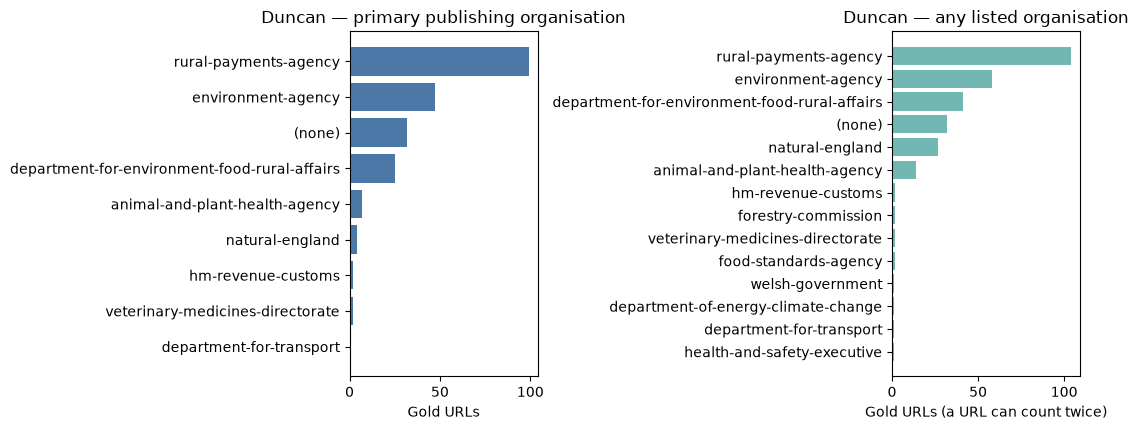

**Primary**

,n,pct
primary_org_filled,,
rural-payments-agency,99,45.2
environment-agency,47,21.5
(none),32,14.6
department-for-environment-food-rural-affairs,25,11.4
animal-and-plant-health-agency,7,3.2
natural-england,4,1.8
hm-revenue-customs,2,0.9
veterinary-medicines-directorate,2,0.9
department-for-transport,1,0.5


**Any listed**

,urls,pct
organisations_filled,,
rural-payments-agency,104,47.5
environment-agency,58,26.5
department-for-environment-food-rural-affairs,41,18.7
(none),32,14.6
natural-england,27,12.3
animal-and-plant-health-agency,14,6.4
hm-revenue-customs,2,0.9
forestry-commission,2,0.9
veterinary-medicines-directorate,2,0.9


**Primary × filter outcome**

stage,kept,dropped,not_in_corpus,n
primary_org_filled,,,,
rural-payments-agency,59,40,0,99
environment-agency,23,24,0,47
(none),0,0,32,32
department-for-environment-food-rural-affairs,11,14,0,25
animal-and-plant-health-agency,3,4,0,7
natural-england,3,1,0,4
hm-revenue-customs,0,2,0,2
veterinary-medicines-directorate,1,1,0,2
department-for-transport,0,1,0,1


,primary_org_filled,org_source,stage,title,original
13,(none),none,not_in_corpus,basic-overwinter-stubble-ab2,https://www.gov.uk/countryside-stewardship-grants/basic-overwinter-stubble-ab2
14,(none),none,not_in_corpus,whole-crop-cereals-ab7,https://www.gov.uk/countryside-stewardship-grants/whole-crop-cereals-ab7
55,(none),none,not_in_corpus,apply-for-a-large-countryside-productivity-grant-alpha-assessment,https://www.gov.uk/service-standard-reports/apply-for-a-large-countryside-productivity-grant-alpha-assessment
56,(none),none,not_in_corpus,apply-for-a-large-countryside-productivity-grant-alpha-reassessment,https://www.gov.uk/service-standard-reports/apply-for-a-large-countryside-productivity-grant-alpha-reassessment
60,(none),none,not_in_corpus,bird-flu-licence-for-spreading-or-moving-used-poultry-litter-manure-and-slurry-from-a-protection-or-surveillance-zone-exd353hpaigb,https://www.gov.uk/government/publications/bird-flu-licence-for-spreading-or-moving-used-poultry-litter-manure-and-slurry-from-a-protection-or-surveillance-...
...,...,...,...,...,...
186,rural-payments-agency,own,pass2_keep,Slurry Infrastructure grant round 2: guidance for invited applicants,https://www.gov.uk/government/publications/slurry-infrastructure-grant-round-2-applicant-guidance
188,rural-payments-agency,parent,pass2_keep,Slurry items and specifications – Farming Equipment and Technology Fund (FETF) 2024,https://www.gov.uk/government/publications/farming-equipment-and-technology-fund-2024/slurry-items-and-specifications-farming-equipment-and-technology-fund-...
204,rural-payments-agency,own,pass2_keep,TE4: Supply and plant tree,https://www.gov.uk/countryside-stewardship-grants/supply-and-plant-tree-te4
104,veterinary-medicines-directorate,own,pass2_drop,Guidelines and guidance on the responsible use of veterinary medicines,https://www.gov.uk/guidance/guidelines-and-guidance-on-the-responsible-use-of-antibiotics


In [9]:
if "gold" not in globals():
    raise RuntimeError("Run the Duncan join cell first")


def _gold_parent_path(url: str) -> str | None:
    path = govuk_path(url)
    if not path:
        return None
    parts = path.split("/")
    try:
        i = parts.index("publications")
    except ValueError:
        return None
    if len(parts) > i + 2:
        return "/".join(parts[: i + 2])
    return None


by_path_org = {}
for _, r in pages.iterrows():
    path = govuk_path(r["url"])
    if path:
        by_path_org[path] = r


def _fill_gold_org(row: pd.Series) -> pd.Series:
    primary = row.get("primary_org") or ""
    orgs = list(row.get("organisations") or [])
    source = "own" if (primary or orgs) else "none"
    if not primary and not orgs:
        for src in (row.get("corpus_url") or "", row.get("original") or ""):
            par = _gold_parent_path(src)
            if par and par in by_path_org:
                p = by_path_org[par]
                primary = p["primary_org"] or ""
                orgs = list(p["organisations"] or [])
                source = "parent" if (primary or orgs) else "none"
                break
    return pd.Series(
        {
            "primary_org_filled": primary or "(none)",
            "organisations_filled": orgs,
            "org_source": source,
        }
    )


gold = gold.join(gold.apply(_fill_gold_org, axis=1))
n_gold = len(gold)
n_unknown = int((gold["primary_org_filled"] == "(none)").sum())
display(Markdown(
    f"**{n_gold}** unique Duncan originals · "
    f"{int((gold['org_source'] == 'own').sum())} own org · "
    f"{int((gold['org_source'] == 'parent').sum())} inherited from parent · "
    f"{n_unknown} unknown (not in corpus)"
))

primary = (
    gold["primary_org_filled"]
    .value_counts()
    .rename("n")
    .to_frame()
    .assign(pct=lambda d: (d["n"] / n_gold * 100).round(1))
)
any_org = (
    gold["organisations_filled"]
    .explode()
    .fillna("(none)")
    .replace("", "(none)")
    .value_counts()
    .rename("urls")
    .to_frame()
    .assign(pct=lambda d: (d["urls"] / n_gold * 100).round(1))
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].barh(list(primary.index[::-1]), primary["n"].to_numpy()[::-1], color="#4C78A8")
axes[0].set_title("Duncan — primary publishing organisation")
axes[0].set_xlabel("Gold URLs")
axes[1].barh(list(any_org.index[::-1]), any_org["urls"].to_numpy()[::-1], color="#72B7B2")
axes[1].set_title("Duncan — any listed organisation")
axes[1].set_xlabel("Gold URLs (a URL can count twice)")
fig.tight_layout()
plt.show()

display(Markdown("**Primary**"))
display(primary)
display(Markdown("**Any listed**"))
display(any_org)

bucket = gold["stage"].astype(str).map(
    lambda s: "kept" if s in {"pass2_keep", "pass2_unadjudicated"}
    else ("not_in_corpus" if s == "not_in_corpus" else "dropped")
)
crosstab = (
    pd.crosstab(gold["primary_org_filled"], bucket)
    .reindex(columns=["kept", "dropped", "not_in_corpus"], fill_value=0)
)
crosstab["n"] = crosstab.sum(axis=1)
crosstab = crosstab.sort_values("n", ascending=False)
display(Markdown("**Primary × filter outcome**"))
display(crosstab)
display(gold[["primary_org_filled", "org_source", "stage", "title", "original"]].sort_values(
    ["primary_org_filled", "stage"]
))
